# Grid Contingency Analysis
## Which single failures hurt the grid? How does a failure spread? 

Import necessary packages.

---

In [2]:
import numpy as np
import pandas as pd 
# import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn
import pandapower.topology as top
import pandapower.plotting as plot

In [3]:
# load benchmark IEEE 14-bus network
net = pn.power_system_test_cases.case14()

# run standard AC power flow
pp.runpp(net)

# get all transmission lines, put in array
lines = net.line.index.tolist()
# plot.simple_plot(net, plot_loads=True, plot_gens=True)

Establish the N-0 case for the IEEE 14-bus system. This serves as a baseline for comparison for N-K contingencies.

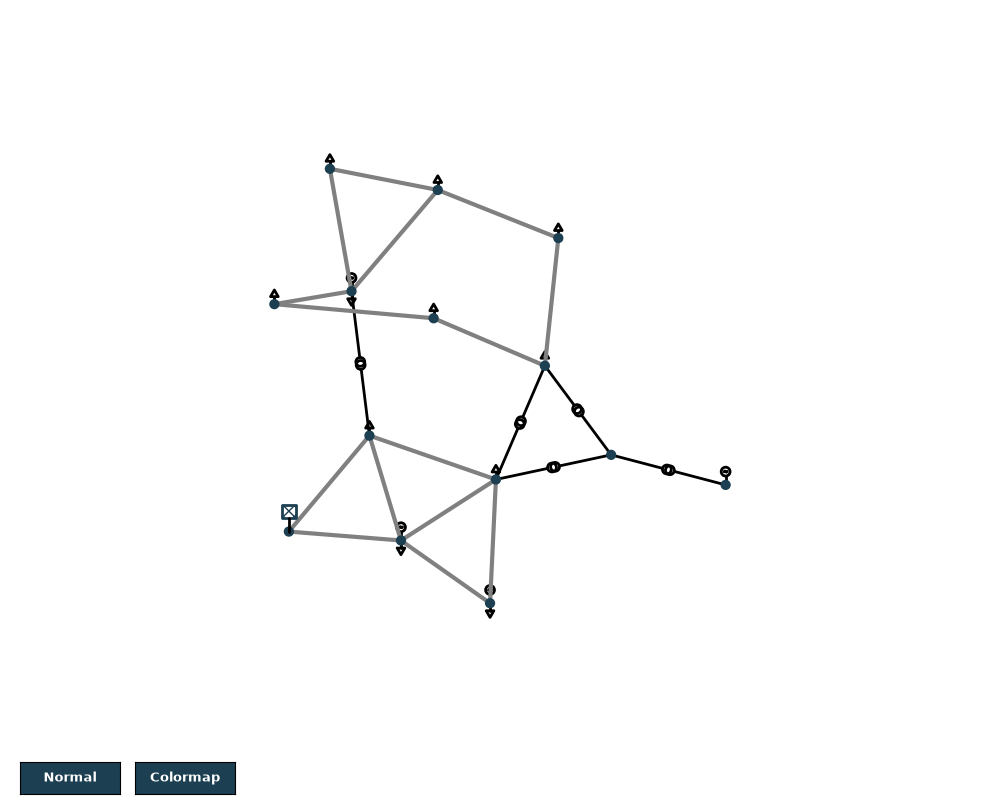

<Axes: >

In [4]:
# N-0 case (for comparison)
v_min, v_max, load_max = 0.95, 1.10, 100 # establish thresholds (limits) to evaluate grid, v_max increased to account for higher max bus voltage

# load buses
gen_buses = set(net.gen.bus) | set(net.ext_grid.bus) # id buses connected to generator and external grid, joins them
pq_buses = [bus for bus in net.bus.index if bus not in gen_buses] # keep buses that are not in gen_buses

# save placeholder limits (original ratings)
default_limits = net.line["max_i_ka"].copy()

# calculate S to determine how much power each line carries (reference for setting current limits)
vn = net.bus.vn_kv[net.line.from_bus].values # get the nominal voltage of the bus where each line begins
base_mva = np.sqrt(3) * vn * net.res_line.i_ka.values # 3-phase formula to find apparent power

# calculate new limits (current ratings) for the max value in each voltage group
for voltage_group in (vn > 100, vn < 100):
    max_mva = 1.5 * base_mva[voltage_group].max()
    net.line.loc[voltage_group, "max_i_ka"] = max_mva / (np.sqrt(3) * vn[voltage_group])

pp.runpp(net) # rerun power flow using new limits
plot.simple_plot(net, plot_loads=True, plot_gens=True)

In [5]:
# check each line against the following conditions: 
# 1. min bus voltage < 0.95 pu
# 2. max bus voltage > 1.10 pu
# 3. number of overloaded > 0
# 4. number of islanded > 0

def check_case(net, n=1.0):
    v = net.res_bus.loc[pq_buses, "vm_pu"] # load buses
    loading = net.res_line["loading_percent"]

    # islanded grid, check separation from main network
    map = top.create_nxgraph(net) # map all true connections
    islands = list(top.connected_components(map))
    # n_islands = len(islands)
    n_islanded = len(top.unsupplied_buses(net))

    n_overload = int((loading > load_max).sum())
    violation = n_overload > 0 or v.min() < v_min or v.max() > v_max or n_islanded > 0
    perf_index_v = ((abs(v-1.0)/0.10)**(2*n)).sum() # delta V represents bus voltage deviation from nominal target voltage (1.0 pu)
    perf_index_l = ((loading/100)**(2*n)).sum() # divide by 100 to get ratio
    return {
        "Status": "Violation" if violation else "Pass",
        "Max_Line_Loading_%": loading.max(),
        "Worst_Line": loading.idxmax(), # idxmax() records first occurrence of max value
        "Lines_Overloaded": n_overload,
        "Min_Bus_V_pu": v.min(),
        "Max_Bus_V_pu": v.max(),
        "Islanded_Buses": n_islanded,
        "PI_V": perf_index_v, 
        "PI_L": perf_index_l,
        "PI_Total": perf_index_v + perf_index_l, 
    }

base_row = check_case(net)
base_row["Tripped_Line"] = "N/A" # ideally, N-0 case should not have any tripped lines
display(pd.DataFrame([base_row]))

,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total,Tripped_Line
0,Pass,66.666667,9,0,1.017671,1.06152,0,2.029032,1.68011,3.709142,N/A


Define a function to observe cascading failures.

In [6]:
# simulate cascading outages
def sim_cascade(net, load_max, start_line):
    load_max = 100
    tripped = [start_line] # record all tripped lines
    net.line.loc[i, "in_service"] = False

    try:
        while True:
            pp.runpp(net) # run power flow

            # loading on active lines
            active_lines = net.line[net.line["in_service"]].index 
            loading = net.res_line.loc[active_lines, "loading_percent"]

            # exit loop (finish) if grid is stable
            if loading.max() <= load_max:
                status = "Stable"
                break

            # trip most overloaded line and go through another iteration
            max_line_loading = loading.idxmax()
            net.line.loc[max_line_loading, "in_service"] = False 
            tripped.append(max_line_loading)


    except pp.LoadflowNotConverged:
        status = "Blackout"
    finally:
        net.line.loc[tripped, "in_service"] = True
    return {
        "Initial_Line": start_line,
        "Cascade_Status": status,
        "Sequence": tripped,
        "Total_Tripped": len(tripped),
    }


Simulate a fault at each line. Find any thermal/voltage violations. Tabulate the results.

,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total,Tripped_Line
0,Violation,111.129095,1,1,0.993484,1.054638,0,1.601267,2.903975,4.505241,0
1,Violation,102.378303,0,1,1.006442,1.057768,0,1.833591,2.288894,4.122485,1
2,Pass,69.730296,9,0,1.011300,1.058220,0,1.832219,2.178073,4.010291,2
3,Pass,69.809807,9,0,1.007096,1.056367,0,1.748227,1.879580,3.627807,3
4,Pass,65.950210,9,0,1.010312,1.058911,0,1.886525,1.620716,3.507241,4
5,Pass,69.089016,0,0,1.020329,1.062841,0,2.111000,1.688746,3.799746,5
6,Pass,82.388286,9,0,1.014003,1.057158,0,1.705066,2.629366,4.334432,6
7,Pass,74.266527,9,0,1.016163,1.057558,0,1.514453,1.947452,3.461905,7
8,Pass,91.964837,9,0,1.017445,1.060977,0,1.675601,2.076729,3.752330,8
9,Pass,71.830796,8,0,0.997979,1.057273,0,1.211593,2.261391,3.472983,9


,Initial_Line,Cascade_Status,Sequence,Total_Tripped
0,0,Stable,[0],1
1,1,Stable,[1],1


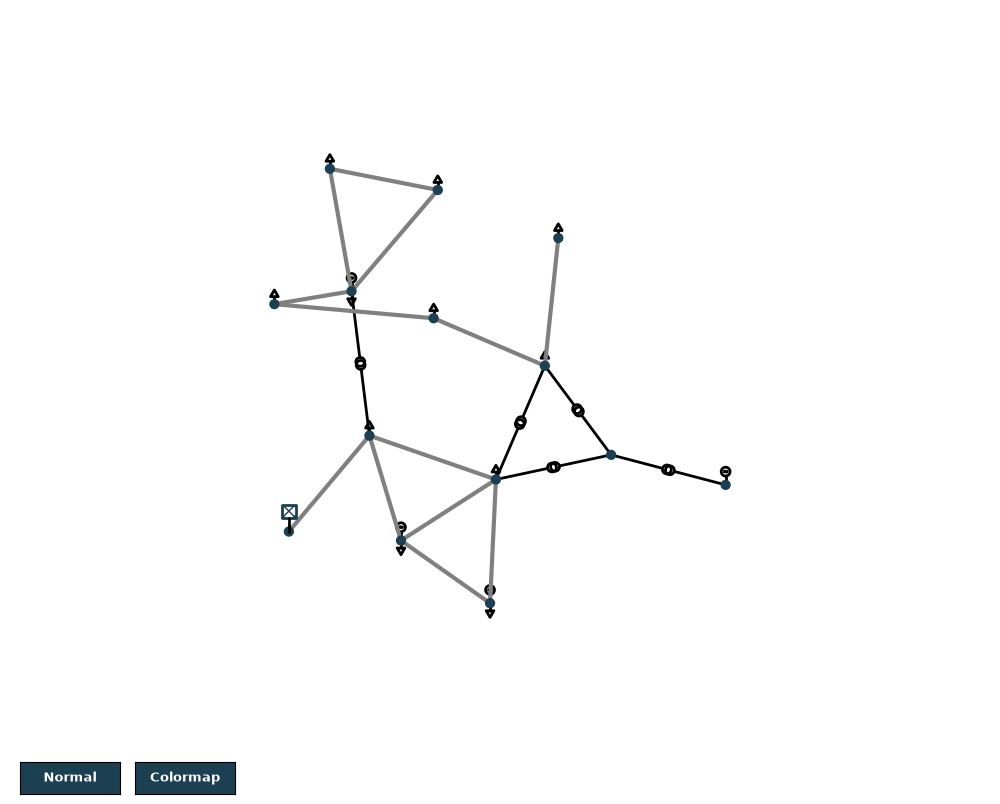

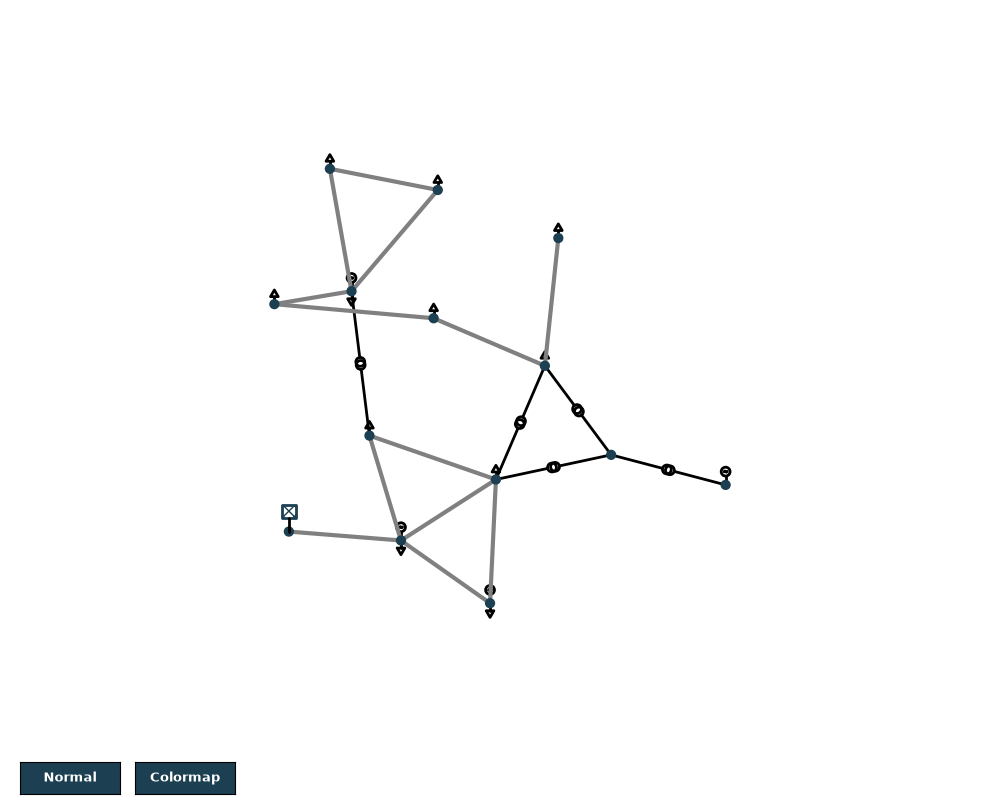

In [7]:
# N-1 case
n1_rows = []

for i in lines:
    # simulate a fault/outage at a given transmission line
    net.line.loc[i, 'in_service'] = False

# exception handling to manage the result of Newton-Ralphson method
    try:
        pp.runpp(net) # recalculate power flow
        row = check_case(net)
    except pp.LoadflowNotConverged:
        row = {"Status": "Non-convergence"}
    finally:
        net.line.loc[i, "in_service"] = True # restore the line
    row["Tripped_Line"] = i
    n1_rows.append(row)

results = pd.DataFrame(n1_rows)
display(results)

# run cascade sim
cascade_rows = []
violation_lines = results.loc[results["Status"]=="Violation", "Tripped_Line"].tolist()

for line_index in violation_lines:
    cascade_result = sim_cascade(net, load_max=load_max, start_line=line_index)
    cascade_rows.append(cascade_result)

cascade_df = pd.DataFrame(cascade_rows)
display(cascade_df)

for n in results.loc[results["Status"]=="Violation", "Tripped_Line"]:
    net.line.loc[n, "in_service"] = False
    plot.simple_plot(net, plot_loads=True, plot_gens=True)
    net.line.loc[n, "in_service"] = True

Sort total PI from greatest to least to identify the most vulnerable lines.

In [8]:
display(results.sort_values(by="PI_Total",ascending=False))

,Status,Max_Line_Loading_%,Worst_Line,Lines_Overloaded,Min_Bus_V_pu,Max_Bus_V_pu,Islanded_Buses,PI_V,PI_L,PI_Total,Tripped_Line
0,Violation,111.129095,1,1,0.993484,1.054638,0,1.601267,2.903975,4.505241,0
11,Pass,97.222256,9,0,0.996870,1.065484,0,2.031903,2.431396,4.463299,11
6,Pass,82.388286,9,0,1.014003,1.057158,0,1.705066,2.629366,4.334432,6
1,Violation,102.378303,0,1,1.006442,1.057768,0,1.833591,2.288894,4.122485,1
2,Pass,69.730296,9,0,1.011300,1.058220,0,1.832219,2.178073,4.010291,2
5,Pass,69.089016,0,0,1.020329,1.062841,0,2.111000,1.688746,3.799746,5
10,Pass,66.601453,0,0,1.019030,1.065403,0,1.898760,1.892330,3.791089,10
13,Pass,72.158785,9,0,1.017622,1.061385,0,2.041020,1.725708,3.766728,13
8,Pass,91.964837,9,0,1.017445,1.060977,0,1.675601,2.076729,3.752330,8
12,Pass,70.522693,9,0,1.016943,1.063496,0,1.960251,1.745125,3.705376,12


Devise a strategy to mitigate the effects of vulnerable line outages.

In [9]:
from pandapower.contingency import run_contingency
nminus1_cases = {"line": {"index": net.line.index.values}}
# print(type(nminus1_cases), type(nminus1_cases["line"]))
res = run_contingency(net, nminus1_cases)
# print(type(res))
for k, v in res.items():
    print(k, type(v))
    if isinstance(v, dict):
        for kk, vv in v.items():
            print("   ", kk, getattr(vv, "shape", type(vv)))

bus_df  = pd.DataFrame(res["bus"])    # e.g., min/max voltage per bus
line_df = pd.DataFrame(res["line"])   # e.g., min/max loading per line
display(bus_df)
display(line_df)

bus <class 'dict'>
    index (14,)
    max_vm_pu (14,)
    min_vm_pu (14,)
    vm_pu (14,)
line <class 'dict'>
    index (15,)
    causes_overloading (15,)
    cause_element (15,)
    cause_index (15,)
    max_loading_percent (15,)
    min_loading_percent (15,)
    loading_percent (15,)
trafo <class 'dict'>
    index (5,)
    causes_overloading (5,)
    cause_element (5,)
    cause_index (5,)
    max_loading_percent (5,)
    min_loading_percent (5,)
    loading_percent (5,)


,index,max_vm_pu,min_vm_pu,vm_pu
0,0,1.060000,1.060000,1.060000
1,1,1.045000,1.045000,1.045000
2,2,1.010000,1.010000,1.010000
3,3,1.021034,1.000394,1.016743
4,4,1.022498,0.992932,1.019232
5,5,1.070000,1.070000,1.070000
6,6,1.065741,1.050329,1.059111
7,7,1.090000,1.090000,1.090000
8,8,1.062786,1.041117,1.051422
9,9,1.056710,1.025385,1.047072


,index,causes_overloading,cause_element,cause_index,max_loading_percent,min_loading_percent,loading_percent
0,0,True,line,0,102.416451,60.463657,66.792963
1,1,True,line,0,111.338346,23.536794,31.828722
2,2,False,line,5,42.054608,21.124939,31.457502
3,3,False,line,2,40.352649,11.808214,24.138791
4,4,False,line,1,33.213971,6.724433,17.718739
5,5,False,line,2,46.751167,3.176027,10.568012
6,6,False,line,0,68.148152,13.256254,28.703362
7,7,False,line,6,84.611393,13.778692,37.622312
8,8,False,line,9,78.310287,22.172228,24.151156
9,9,False,line,8,74.790841,49.760603,49.760603
